In [1]:
%pip install pandas matplotlib


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [3]:
orders = pd.read_csv("orders.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", orders.shape)

display(orders.head())

Dataset loaded successfully!
Rows and columns: (99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
orders.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [7]:
missing_values = orders.isnull().sum()

print("Missing values in each column:")
display(missing_values.to_frame(name="Missing Values"))

Missing values in each column:


,Missing Values
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [8]:
print("Total rows:", len(orders))
print("Exact duplicate rows:", orders.duplicated().sum())
print("Duplicate order IDs:", orders["order_id"].duplicated().sum())
print("Missing order IDs:", orders["order_id"].isnull().sum())

Total rows: 99441
Exact duplicate rows: 0
Duplicate order IDs: 0
Missing order IDs: 0


In [9]:
orders_clean = orders.copy()

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders_clean[col] = pd.to_datetime(
        orders_clean[col],
        errors="coerce"
    )

orders_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


In [11]:
# Standardize order status
orders_clean["order_status"] = (
    orders_clean["order_status"]
    .str.strip()
    .str.lower()
)

# Display order status counts
print(orders_clean["order_status"].value_counts())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [12]:
# Check statuses of orders with missing approval dates
print("Missing approval date:")
display(
    orders_clean.loc[
        orders_clean["order_approved_at"].isna(),
        "order_status"
    ].value_counts()
)

# Check statuses of orders with missing delivery dates
print("\nMissing customer delivery date:")
display(
    orders_clean.loc[
        orders_clean["order_delivered_customer_date"].isna(),
        "order_status"
    ].value_counts()
)

Missing approval date:


order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64


Missing customer delivery date:


order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [13]:
print("Total rows:", len(orders_clean))
print("Exact duplicate rows:", orders_clean.duplicated().sum())
print("Duplicate order IDs:", orders_clean["order_id"].duplicated().sum())


Total rows: 99441
Exact duplicate rows: 0
Duplicate order IDs: 0


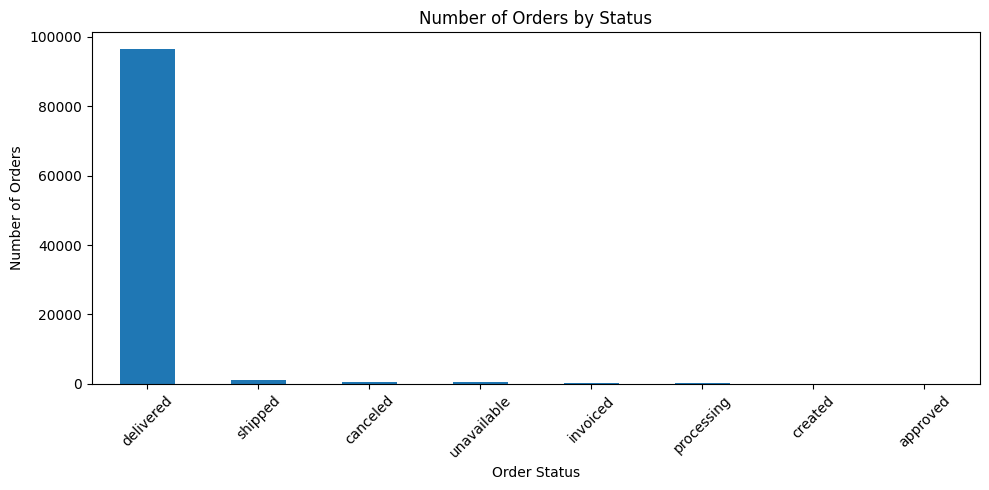

In [14]:
import matplotlib.pyplot as plt

status_counts = orders_clean["order_status"].value_counts()

plt.figure(figsize=(10, 5))
status_counts.plot(kind="bar")

plt.title("Number of Orders by Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

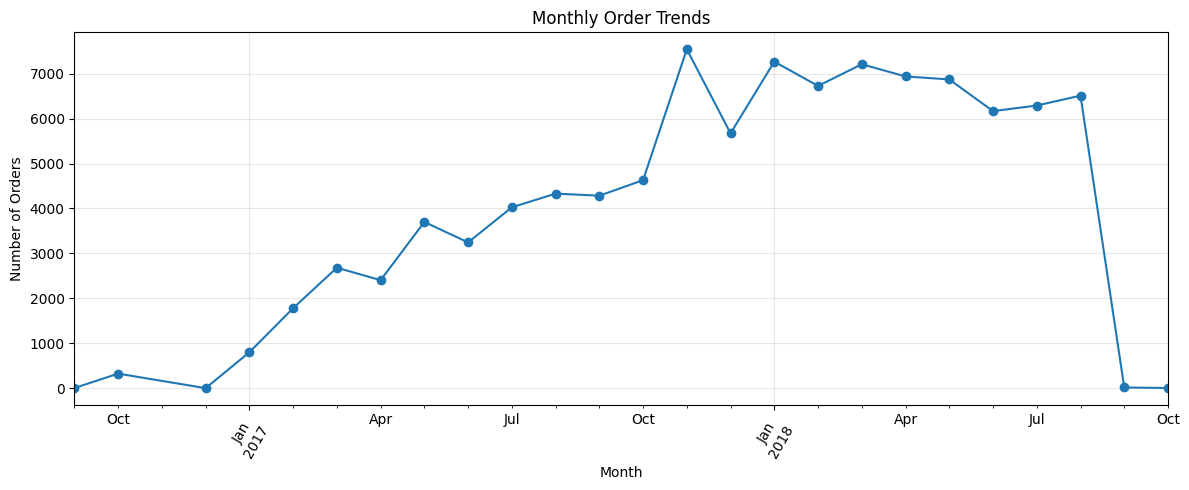

In [17]:
import matplotlib.pyplot as plt

# Extract the purchase month
orders_clean["purchase_month"] = (
    orders_clean["order_purchase_timestamp"]
    .dt.to_period("M")
)

# Count orders per month
monthly_orders = orders_clean.groupby(
    "purchase_month"
).size()

# Plot the monthly trend
plt.figure(figsize=(12, 5))

monthly_orders.plot(
    kind="line",
    marker="o"
)

plt.title("Monthly Order Trends")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

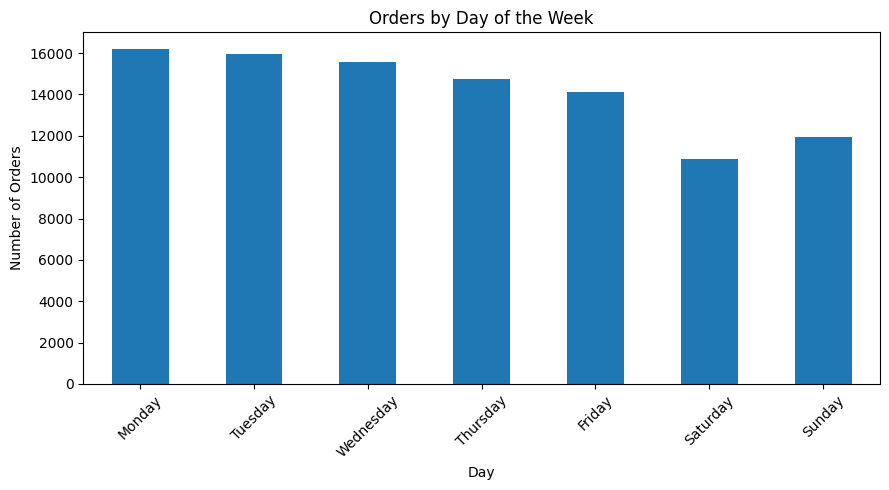

purchase_day
Monday       16196
Tuesday      15963
Wednesday    15552
Thursday     14761
Friday       14122
Saturday     10887
Sunday       11960
Name: count, dtype: int64


In [18]:
orders_clean["purchase_day"] = (
    orders_clean["order_purchase_timestamp"].dt.day_name()
)

day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_counts = (
    orders_clean["purchase_day"]
    .value_counts()
    .reindex(day_order, fill_value=0)
)

plt.figure(figsize=(9, 5))
weekday_counts.plot(kind="bar")

plt.title("Orders by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("charts/orders_by_weekday.png", dpi=300, bbox_inches="tight")
plt.show()

print(weekday_counts)

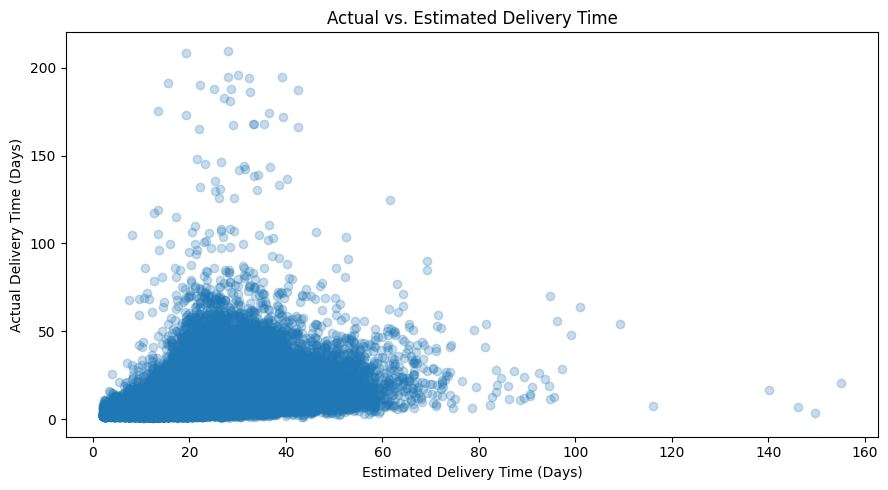

In [20]:
import matplotlib.pyplot as plt

delivery_data = orders_clean[
    (orders_clean["order_status"] == "delivered") &
    orders_clean["order_delivered_customer_date"].notna()
].copy()

delivery_data["actual_delivery_days"] = (
    delivery_data["order_delivered_customer_date"]
    - delivery_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

delivery_data["estimated_delivery_days"] = (
    delivery_data["order_estimated_delivery_date"]
    - delivery_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

delivery_data = delivery_data[
    (delivery_data["actual_delivery_days"] >= 0) &
    (delivery_data["estimated_delivery_days"] >= 0)
]

plt.figure(figsize=(9, 5))
plt.scatter(
    delivery_data["estimated_delivery_days"],
    delivery_data["actual_delivery_days"],
    alpha=0.25
)
plt.title("Actual vs. Estimated Delivery Time")
plt.xlabel("Estimated Delivery Time (Days)")
plt.ylabel("Actual Delivery Time (Days)")
plt.tight_layout()
plt.savefig("charts/actual_vs_estimated_delivery.png", dpi=300)
plt.show()